файлы лежат на публичном гите https://github.com/esaulovads/HW5

## Задание 1. Сборка и публикация образа

#### Образ

In [9]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw5/audit-svc
docker build -q --tag audit-svc:test .
docker run --rm --entrypoint id audit-svc:test
docker run --rm --user root --entrypoint grep audit-svc:test '^user:' /etc/shadow
docker image ls audit-svc
EOF

DEPRECATED: The legacy builder is deprecated and will be removed in a future release.
            Install the buildx component to build images with BuildKit:
            https://docs.docker.com/go/buildx/



sha256:7a09addbf7e73cfb7e2ffcbd5b5110f78a65ee7b4e77700fbf167adb64d1fc50
uid=1001(user) gid=1001(user) groups=1001(user),100(users)
user:!:10957:0:99999:7:::
IMAGE            ID             DISK USAGE   CONTENT SIZE   EXTRA


audit-svc:test   7a09addbf7e7        243MB           62MB        


In [10]:
%%bash
ssh -T devopshw << 'EOF'
docker run --rm --entrypoint migrate audit-svc:test --help | head -n 3
docker run --rm --entrypoint generate audit-svc:test --help | head -n 3
EOF

usage: migrate [-h] [--config CONFIG]

Apply audit-svc database migrations
usage: generate [-h] [--url URL] [--rate RATE] [--duration DURATION]
                [--invalid-ratio INVALID_RATIO] [--read-ratio READ_RATIO]
                [--concurrency CONCURRENCY]


#### Пайплайн

In [26]:
%%bash
ssh -T devopshw << 'EOF'
TOKEN=$(cat ~/stands/lecture4/.state/gitlab-root-token.txt)
API=http://localhost:8929/api/v4/projects/demo%2Faudit-svc
PIPE=$(curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/pipelines?ref=main&per_page=1" | jq -r '.[0].id')
TEST=$(curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/pipelines/$PIPE/jobs" | jq -r '.[] | select(.name=="Run Tests") | .id')
PUB=$(curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/pipelines/$PIPE/jobs" | jq -r '.[] | select(.name=="Publish Image") | .id')
curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs/$TEST/trace" | sed 's/\x1b\[[0-9;]*[mK]//g' | grep -E 'pytest|collected|passed|Job succeeded'
curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs/$TEST/artifacts/python.junit.xml" | grep -o '<testsuite [^>]*>' | sed 's/hostname="[^"]*"//'
curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs/$PUB/trace" | sed 's/\x1b\[[0-9;]*[mK]//g' | grep -E 'Pushing image|Pushed'
EOF

2026-10-25T10:08:51.811113Z 01O   - Installing pytest (8.4.2)
2026-10-25T10:08:51.852647Z 01O   - Installing pytest-aiohttp (1.1.1)
2026-10-25T10:08:51.875660Z 01O   - Installing pytest-asyncio (0.24.0)
2026-10-25T10:08:52.589787Z 01O $ poetry run pytest --junitxml python.junit.xml
2026-10-25T10:08:54.435931Z 01O platform linux -- Python 3.11.13, pytest-8.4.2, pluggy-1.6.0
2026-10-25T10:08:54.435936Z 01O collected 6 items
2026-10-25T10:08:54.573011Z 01O ============================== 6 passed in 0.08s ===============================
2026-10-25T10:08:56.897496Z 00O Job succeeded
<testsuite name="pytest" errors="0" failures="0" skipped="0" tests="6" time="0.080" timestamp="2026-10-25T10:08:54.415426+00:00" >
2026-10-25T10:09:53.536310Z 01E INFO[0051] Pushing image to harbor.localtest.me:8443/demo/audit-svc:main_493a7b70 
2026-10-25T10:09:54.135320Z 01E INFO[0051] Pushed harbor.localtest.me:8443/demo/audit-svc@sha256:d305b5fc3a5c4f004a10906001a6b311ca04f434991ad0584c549df19bd91891 


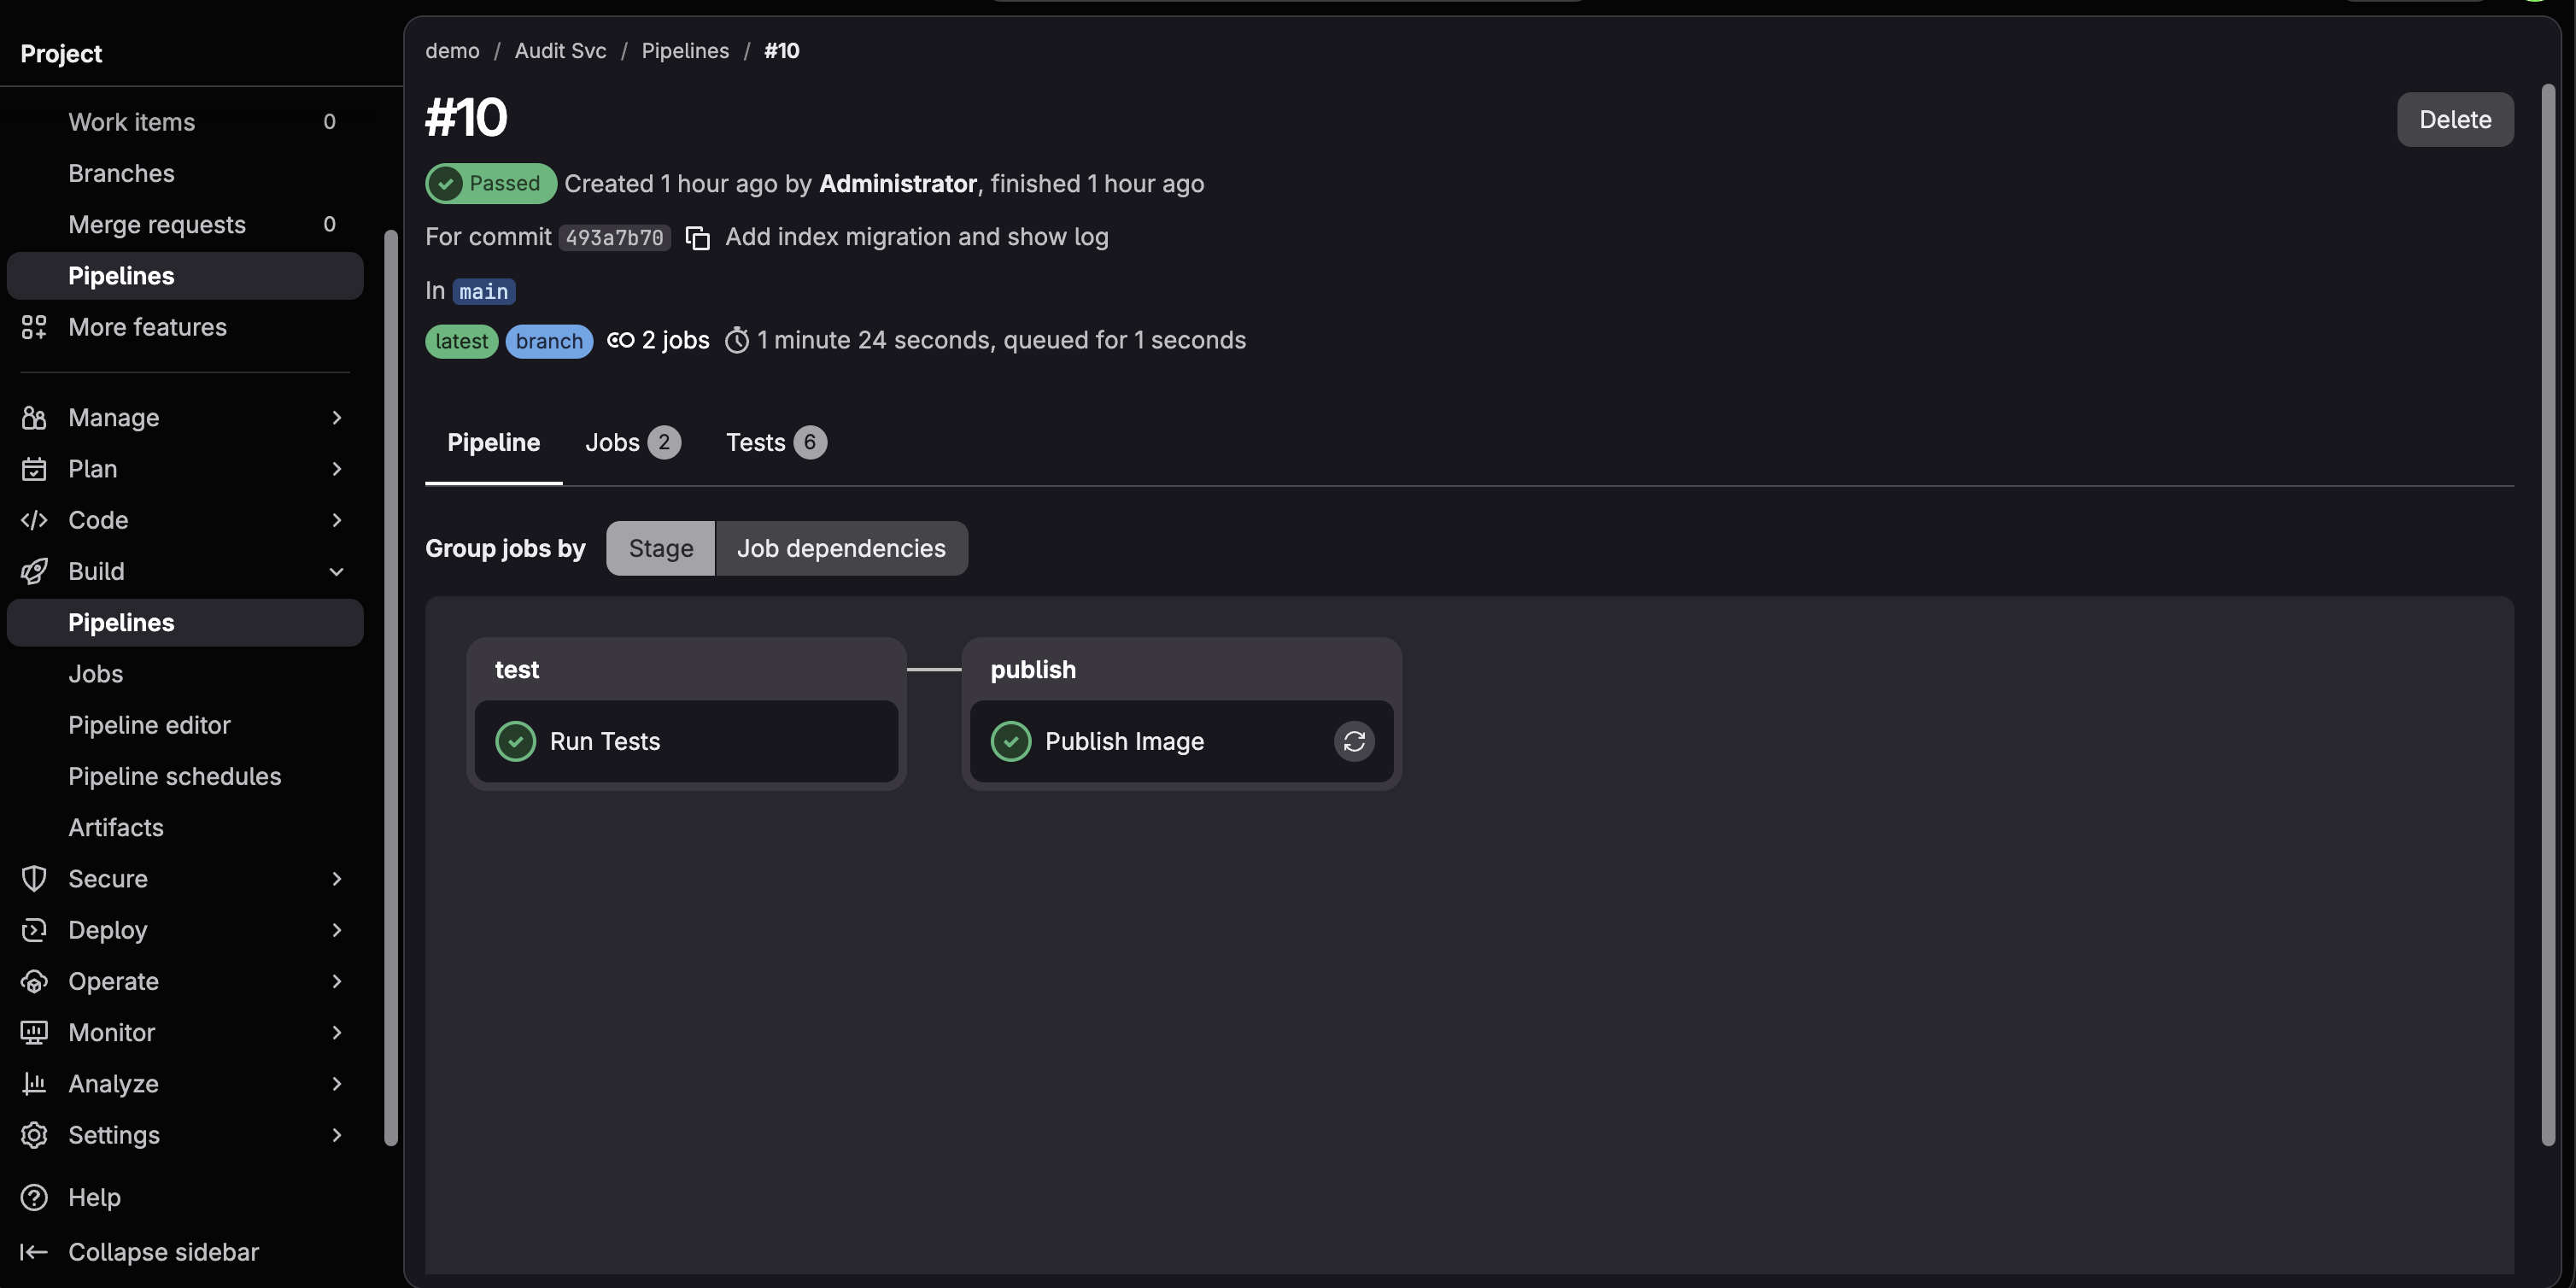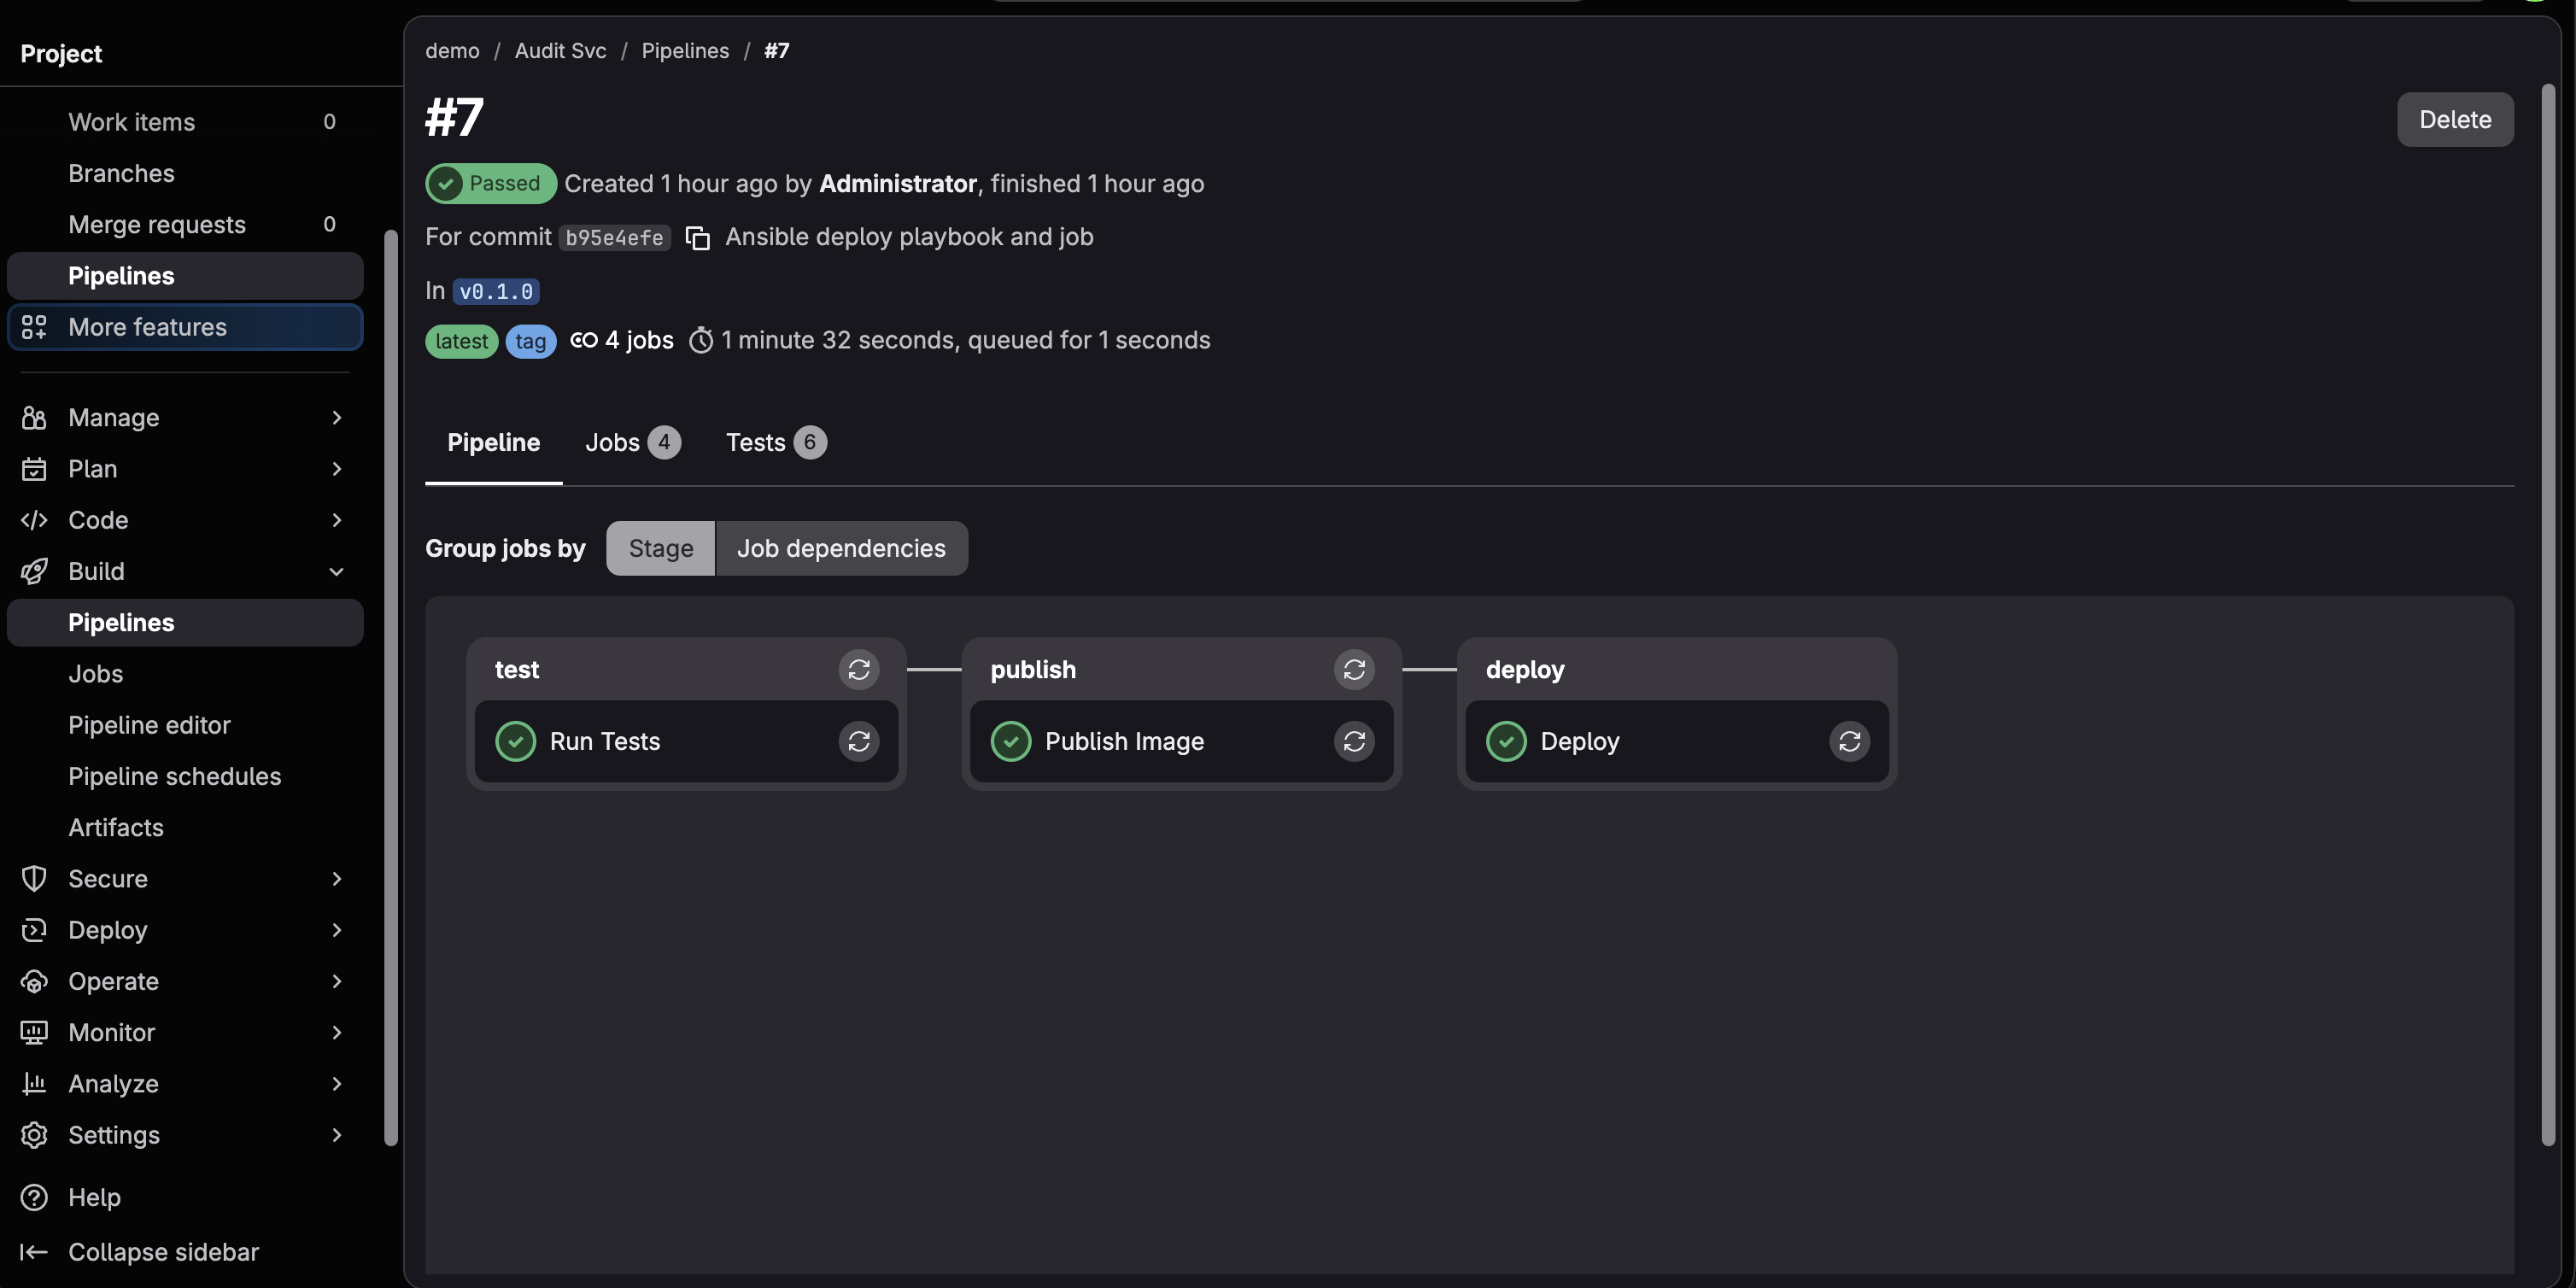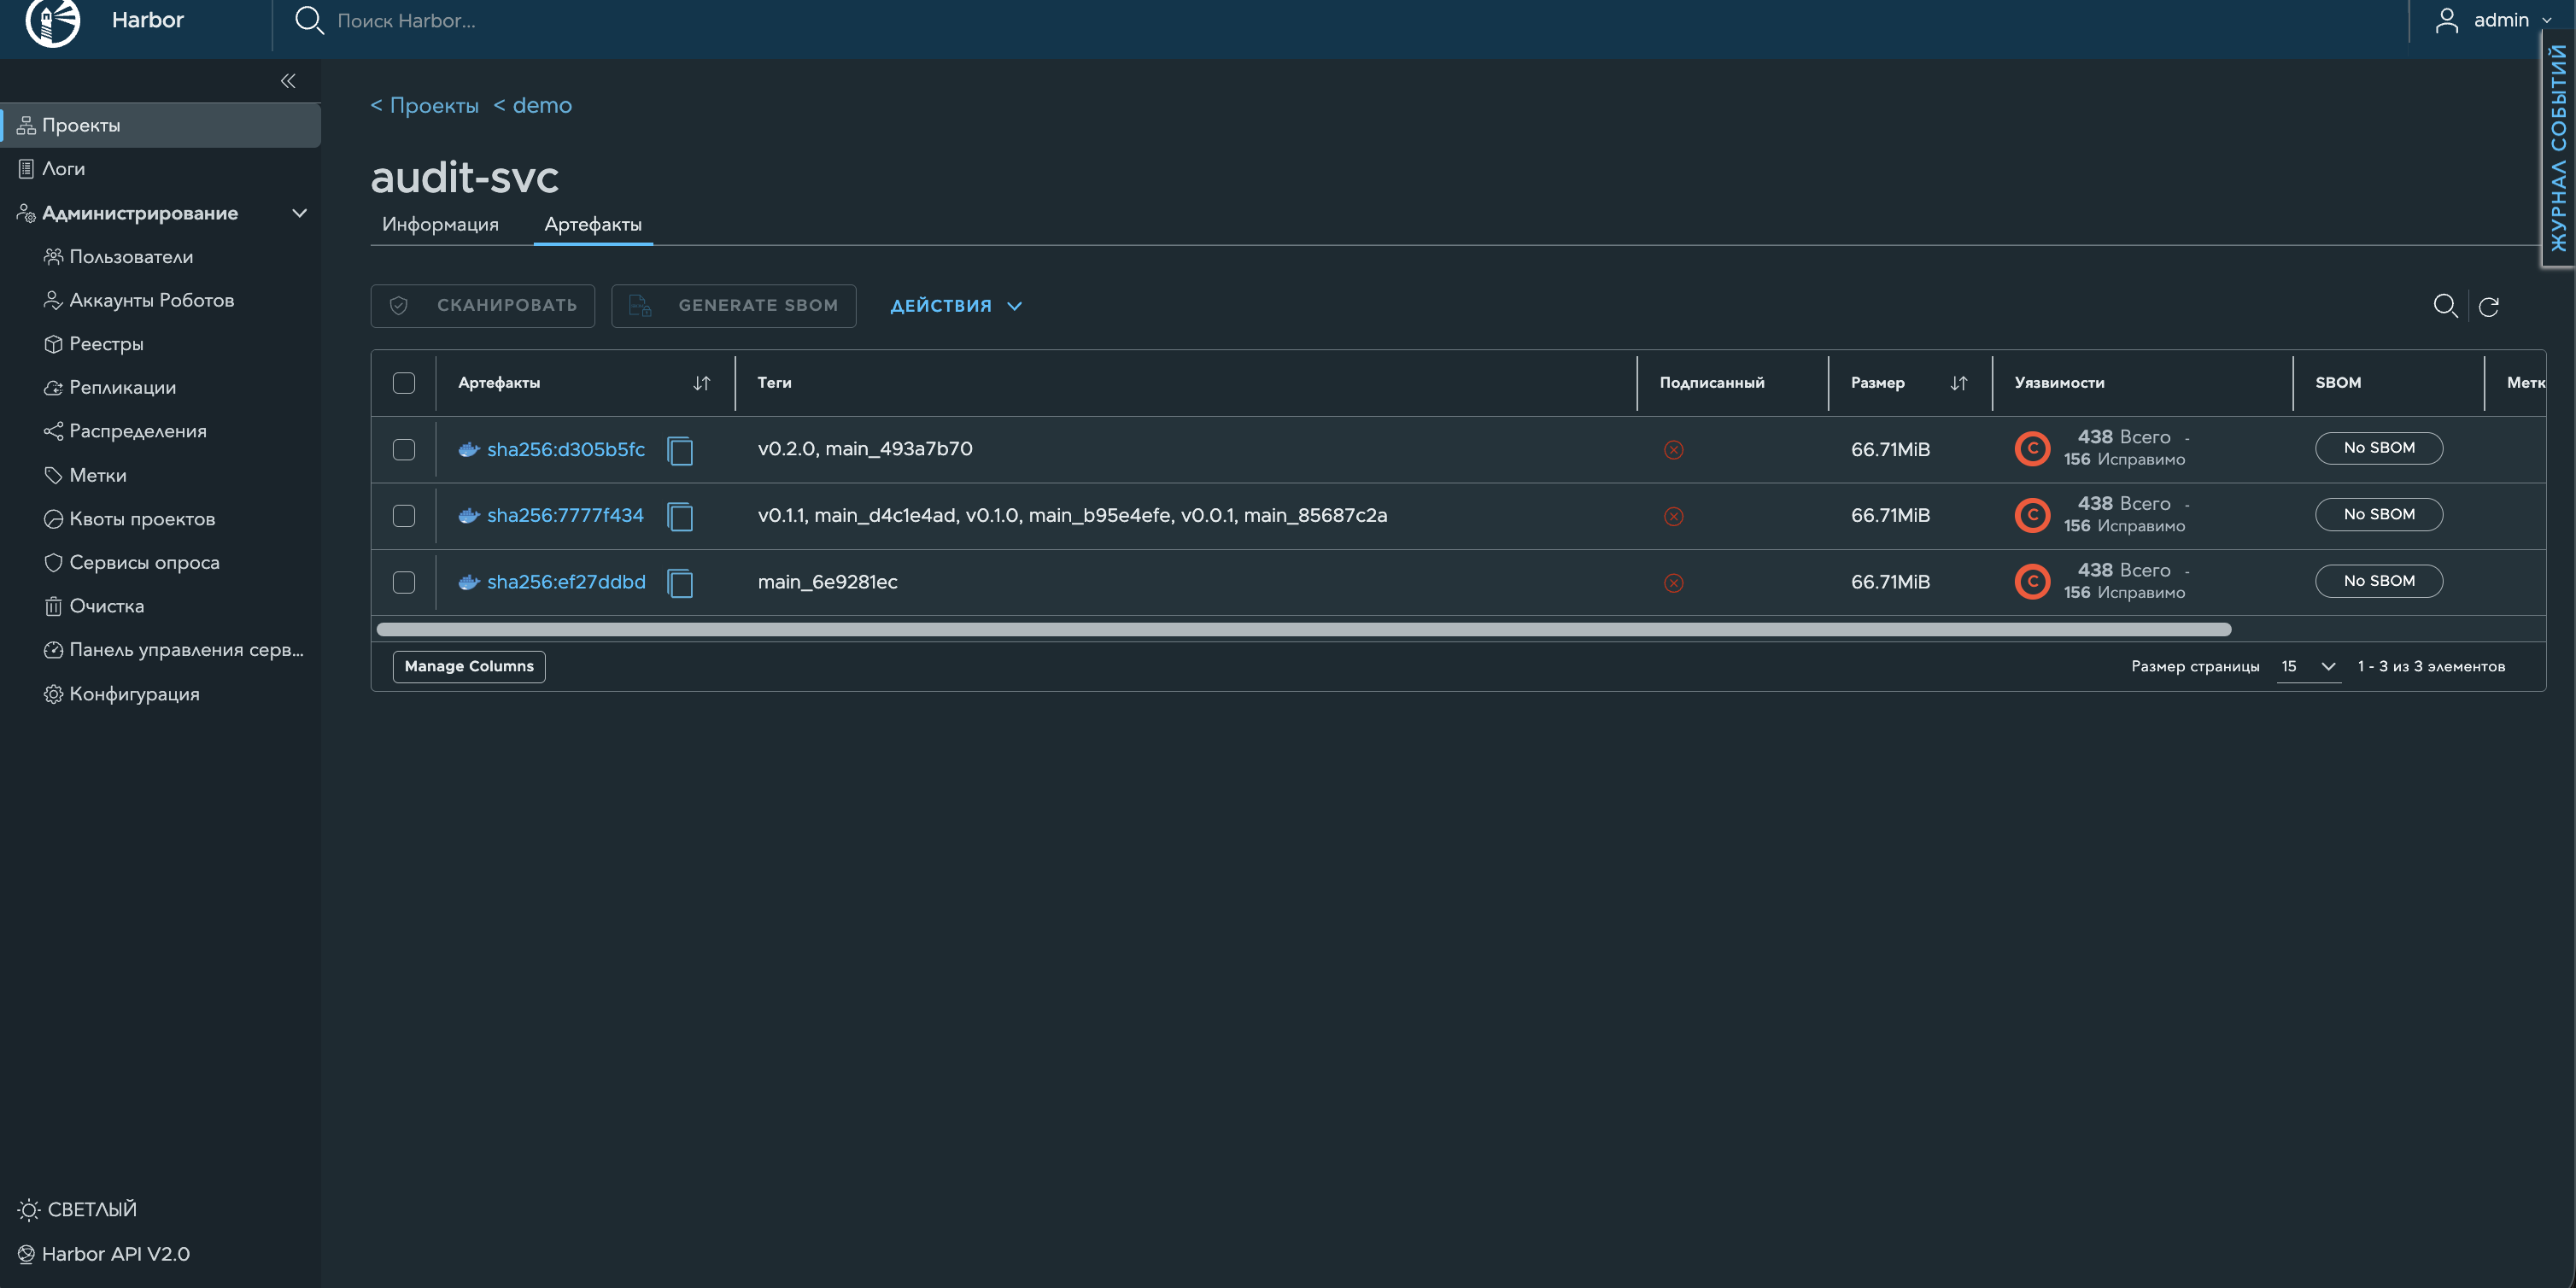

## Задание 2. База данных и секреты

## PostgreSQL, база audit и владелец audit_svc

In [13]:
%%bash
ssh -T devopshw << 'EOF'
docker exec deploy-vm docker volume ls
docker exec deploy-vm docker exec audit-postgres psql -U postgres -c '\l audit' -c '\du'
EOF

DRIVER    VOLUME NAME
local     audit-postgres-data
                                                 List of databases
 Name  |   Owner   | Encoding | Locale Provider |  Collate   |   Ctype    | Locale | ICU Rules | Access privileges 
-------+-----------+----------+-----------------+------------+------------+--------+-----------+-------------------
 audit | audit_svc | UTF8     | libc            | en_US.utf8 | en_US.utf8 |        |           | 
(1 row)

                             List of roles
 Role name |                         Attributes                         
-----------+------------------------------------------------------------
 audit_svc | 
 postgres  | Superuser, Create role, Create DB, Replication, Bypass RLS



## Задание 3. Развёртывание из CI

#### Логи

In [36]:
%%bash
ssh -T devopshw << 'EOF'
TOKEN=$(cat ~/stands/lecture4/.state/gitlab-root-token.txt)
API=http://localhost:8929/api/v4/projects/demo%2Faudit-svc
JOB=$(curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs?per_page=100" | jq -r '[.[] | select(.ref=="v0.1.0" and .name=="Deploy")] | sort_by(.id) | .[0].id')
curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs/$JOB/trace" | sed 's/\x1b\[[0-9;]*[mK]//g' | grep -v section_
EOF

2026-10-25T09:44:23.868917Z 00O Running with gitlab-runner 19.5.1 (f411f264)
2026-10-25T09:44:23.868957Z 00O   on deploy-vm fDCnhKuuN, system ID: r_ENrFMnmiwxfm
2026-10-25T09:44:23.868960Z 00O   UUID: 01a1721a-6e84-7b34-ab67-d8cb040fcda9
2026-10-25T09:44:23.869038Z 00O+Preparing the "shell" executor
2026-10-25T09:44:23.869346Z 00O Using Shell (bash) executor...
2026-10-25T09:44:23.869815Z 00O+Preparing environment
2026-10-25T09:44:23.896441Z 01O Running on deploy-vm...
2026-10-25T09:44:23.902561Z 01O Running on CPU: AMD EPYC 7763 64-Core Processor (avx, avx2)
2026-10-25T09:44:23.910382Z 00O+Getting source from Git repository
2026-10-25T09:44:23.972949Z 01O Gitaly correlation ID: 01M5S74TFZSS3T18X8XQXSS40S
2026-10-25T09:44:23.982838Z 01O Fetching changes with git depth set to 20...
2026-10-25T09:44:23.986499Z 01O Initialized empty Git repository in /data/gitlab-runner/builds/demo-audit-svc/.git/
2026-10-25T09:44:23.989937Z 01O Created fresh repository.
2026-10-25T09:44:24.632275Z 01O Ch

In [37]:
%%bash
ssh -T devopshw << 'EOF'
TOKEN=$(cat ~/stands/lecture4/.state/gitlab-root-token.txt)
API=http://localhost:8929/api/v4/projects/demo%2Faudit-svc
JOB=$(curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs?per_page=100" | jq -r '[.[] | select(.ref=="v0.2.4" and .name=="Deploy")] | sort_by(.id) | .[-1].id')
curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs/$JOB/trace" | sed 's/\x1b\[[0-9;]*[mK]//g' | grep -v section_ | sed -n '/PLAY \[/,$p'
EOF

2026-10-25T14:24:56.713530Z 01O PLAY [Deploy audit-svc] ********************************************************
2026-10-25T14:24:56.713532Z 01O 
2026-10-25T14:24:56.713532Z 01O TASK [Gathering Facts] *********************************************************
2026-10-25T14:24:57.647737Z 01O ok: [prom]
2026-10-25T14:24:57.647748Z 01O 
2026-10-25T14:24:57.647749Z 01O TASK [Create docker network] ***************************************************
2026-10-25T14:24:58.222293Z 01O ok: [prom]
2026-10-25T14:24:58.222306Z 01O 
2026-10-25T14:24:58.222307Z 01O TASK [Create config directory] *************************************************
2026-10-25T14:24:58.572640Z 01O ok: [prom]
2026-10-25T14:24:58.572653Z 01O 
2026-10-25T14:24:58.572654Z 01O TASK [Create nginx directory] **************************************************
2026-10-25T14:24:58.801951Z 01O ok: [prom]
2026-10-25T14:24:58.801962Z 01O 
2026-10-25T14:24:58.801962Z 01O TASK [Pull audit-svc image] **************************************

#### Смена пароля

In [38]:
%%bash
ssh -T devopshw << 'EOF'
docker exec deploy-vm docker inspect -f '{{.State.StartedAt}}' audit-svc
curl -s localhost:8088/metrics | grep audit_config_reloads_total
curl -s -o /dev/null -w '%{http_code}\n' localhost:8088/healthz
EOF

2026-10-25T12:33:03.583510477Z
# HELP audit_config_reloads_total Перечитывания конфигурации
# TYPE audit_config_reloads_total counter
audit_config_reloads_total{result="success"} 1.0
200


Поменяла пароль `audit_svc` через `ansible-vault edit`, закоммитила и выпустила тег v0.2.5

In [40]:
%%bash
ssh -T devopshw << 'EOF'
TOKEN=$(cat ~/stands/lecture4/.state/gitlab-root-token.txt)
API=http://localhost:8929/api/v4/projects/demo%2Faudit-svc
JOB=$(curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs?per_page=100" | jq -r '[.[] | select(.ref=="v0.2.5" and .name=="Deploy")] | sort_by(.id) | .[0].id')
curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs/$JOB/trace" | sed 's/\x1b\[[0-9;]*[mK]//g' | grep -v section_ | sed -n '/PLAY \[/,$p'
EOF

2026-10-25T14:36:15.884830Z 01O PLAY [Deploy audit-svc] ********************************************************
2026-10-25T14:36:15.884831Z 01O 
2026-10-25T14:36:15.884832Z 01O TASK [Gathering Facts] *********************************************************
2026-10-25T14:36:16.887488Z 01O ok: [prom]
2026-10-25T14:36:16.887500Z 01O 
2026-10-25T14:36:16.887501Z 01O TASK [Create docker network] ***************************************************
2026-10-25T14:36:17.468933Z 01O ok: [prom]
2026-10-25T14:36:17.468944Z 01O 
2026-10-25T14:36:17.468944Z 01O TASK [Create config directory] *************************************************
2026-10-25T14:36:17.827966Z 01O ok: [prom]
2026-10-25T14:36:17.827977Z 01O 
2026-10-25T14:36:17.827979Z 01O TASK [Create nginx directory] **************************************************
2026-10-25T14:36:18.061233Z 01O ok: [prom]
2026-10-25T14:36:18.061244Z 01O 
2026-10-25T14:36:18.061244Z 01O TASK [Pull audit-svc image] **************************************

In [41]:
%%bash
ssh -T devopshw << 'EOF'
docker exec deploy-vm docker inspect -f '{{.State.StartedAt}}' audit-svc
docker exec deploy-vm docker logs audit-svc 2>&1 | grep 'config reloaded'
curl -s localhost:8088/metrics | grep '^audit_config_reloads_total'
curl -s -o /dev/null -w '%{http_code}\n' localhost:8088/healthz
EOF

2026-10-25T12:33:03.583510477Z
2026-10-25 14:20:16,276 [INFO] audit_svc.main: config reloaded, database settings are unchanged
2026-10-25 14:36:24,875 [INFO] audit_svc.main: config reloaded, reconnected to the database
audit_config_reloads_total{result="success"} 2.0
200


## Задание 4. Nginx и nginx-exporter

#### Проверки Nginx

In [21]:
%%bash
ssh -T devopshw << 'EOF'
curl -s localhost:8088/healthz
docker exec deploy-vm docker logs audit-svc 2>&1 | grep -c 'config reload'
curl -s -o /dev/null -w '%{http_code}\n' -X POST localhost:8088/reload
curl -s -o /dev/null -w '%{http_code}\n' -X POST 'localhost:8088/reload?x=1'
curl -s -o /dev/null -w '%{http_code}\n' -X POST localhost:8088//reload
curl -s -o /dev/null -w '%{http_code}\n' -X POST localhost:8088/%72eload
docker exec deploy-vm docker logs audit-svc 2>&1 | grep -c 'config reload'
docker exec deploy-vm docker ps --format '{{.Names}}\t{{.Ports}}'
curl -s -o /dev/null -w '%{http_code}\n' localhost:8088/stub_status
docker exec deploy-vm curl -s localhost:9113/metrics | grep '^nginx_up'
EOF

{"status": "ok"}0
404
404
404
404
0
audit-svc	8080/tcp
nginx-exporter	0.0.0.0:9113->9113/tcp
nginx	80/tcp, 0.0.0.0:8080->8080/tcp
audit-postgres	5432/tcp
404
nginx_up 1


## Задание 5. Мониторинг

#### Цели Prometheus
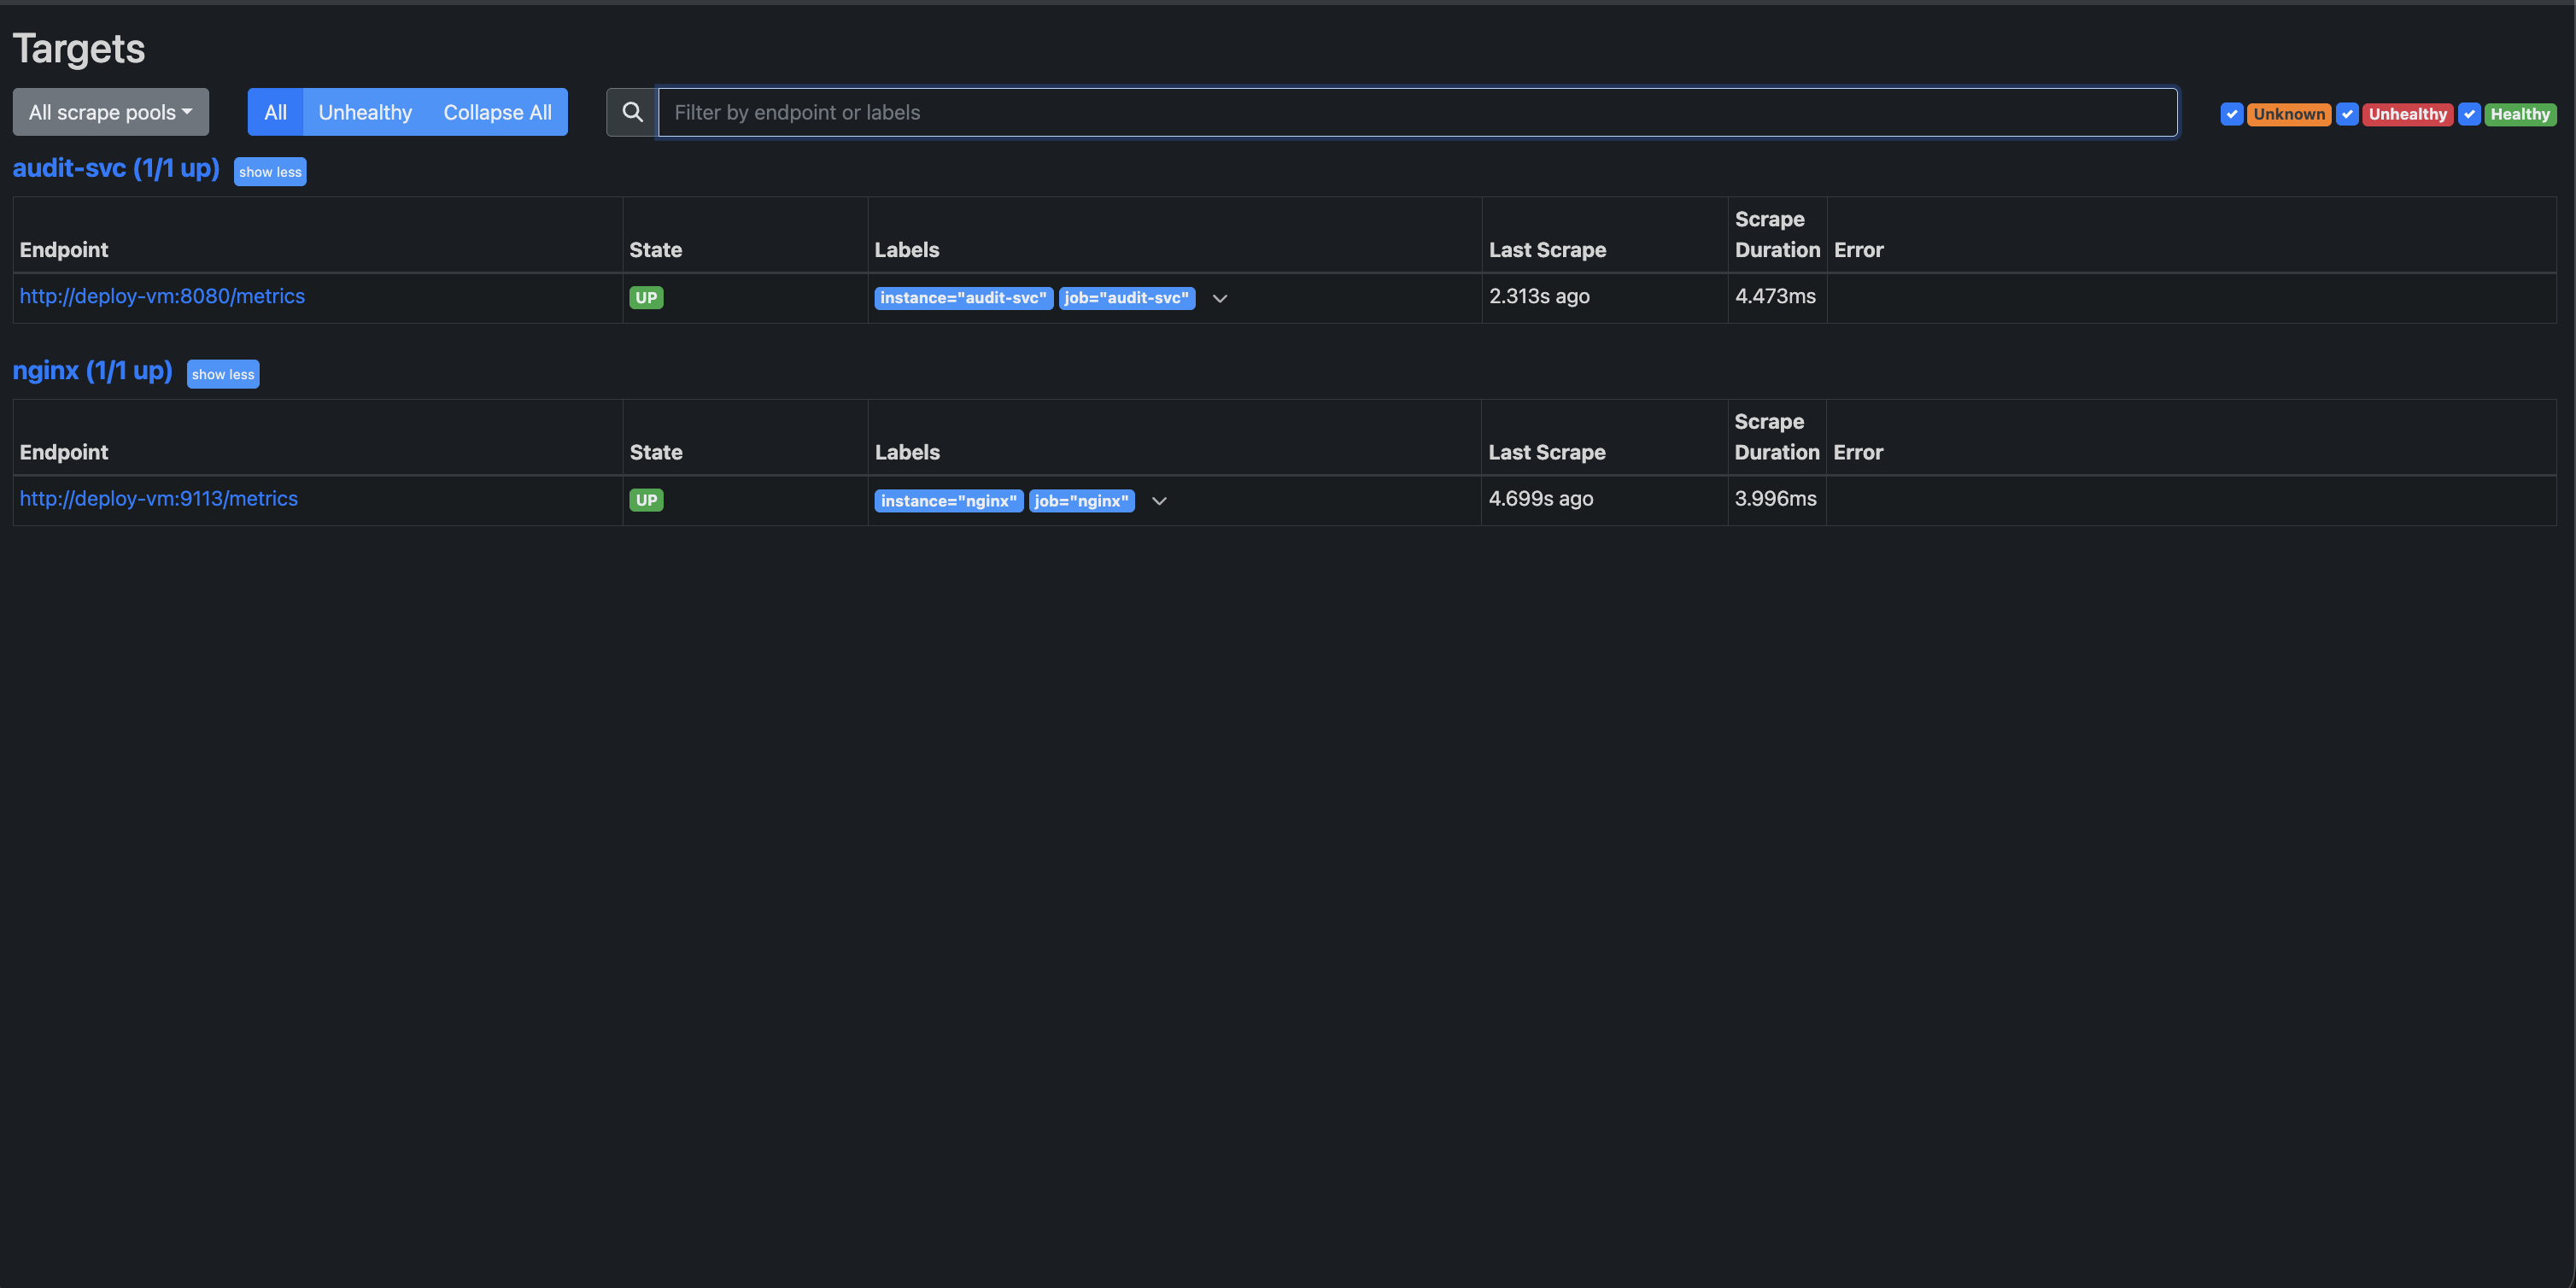

#### Дашборд сервиса
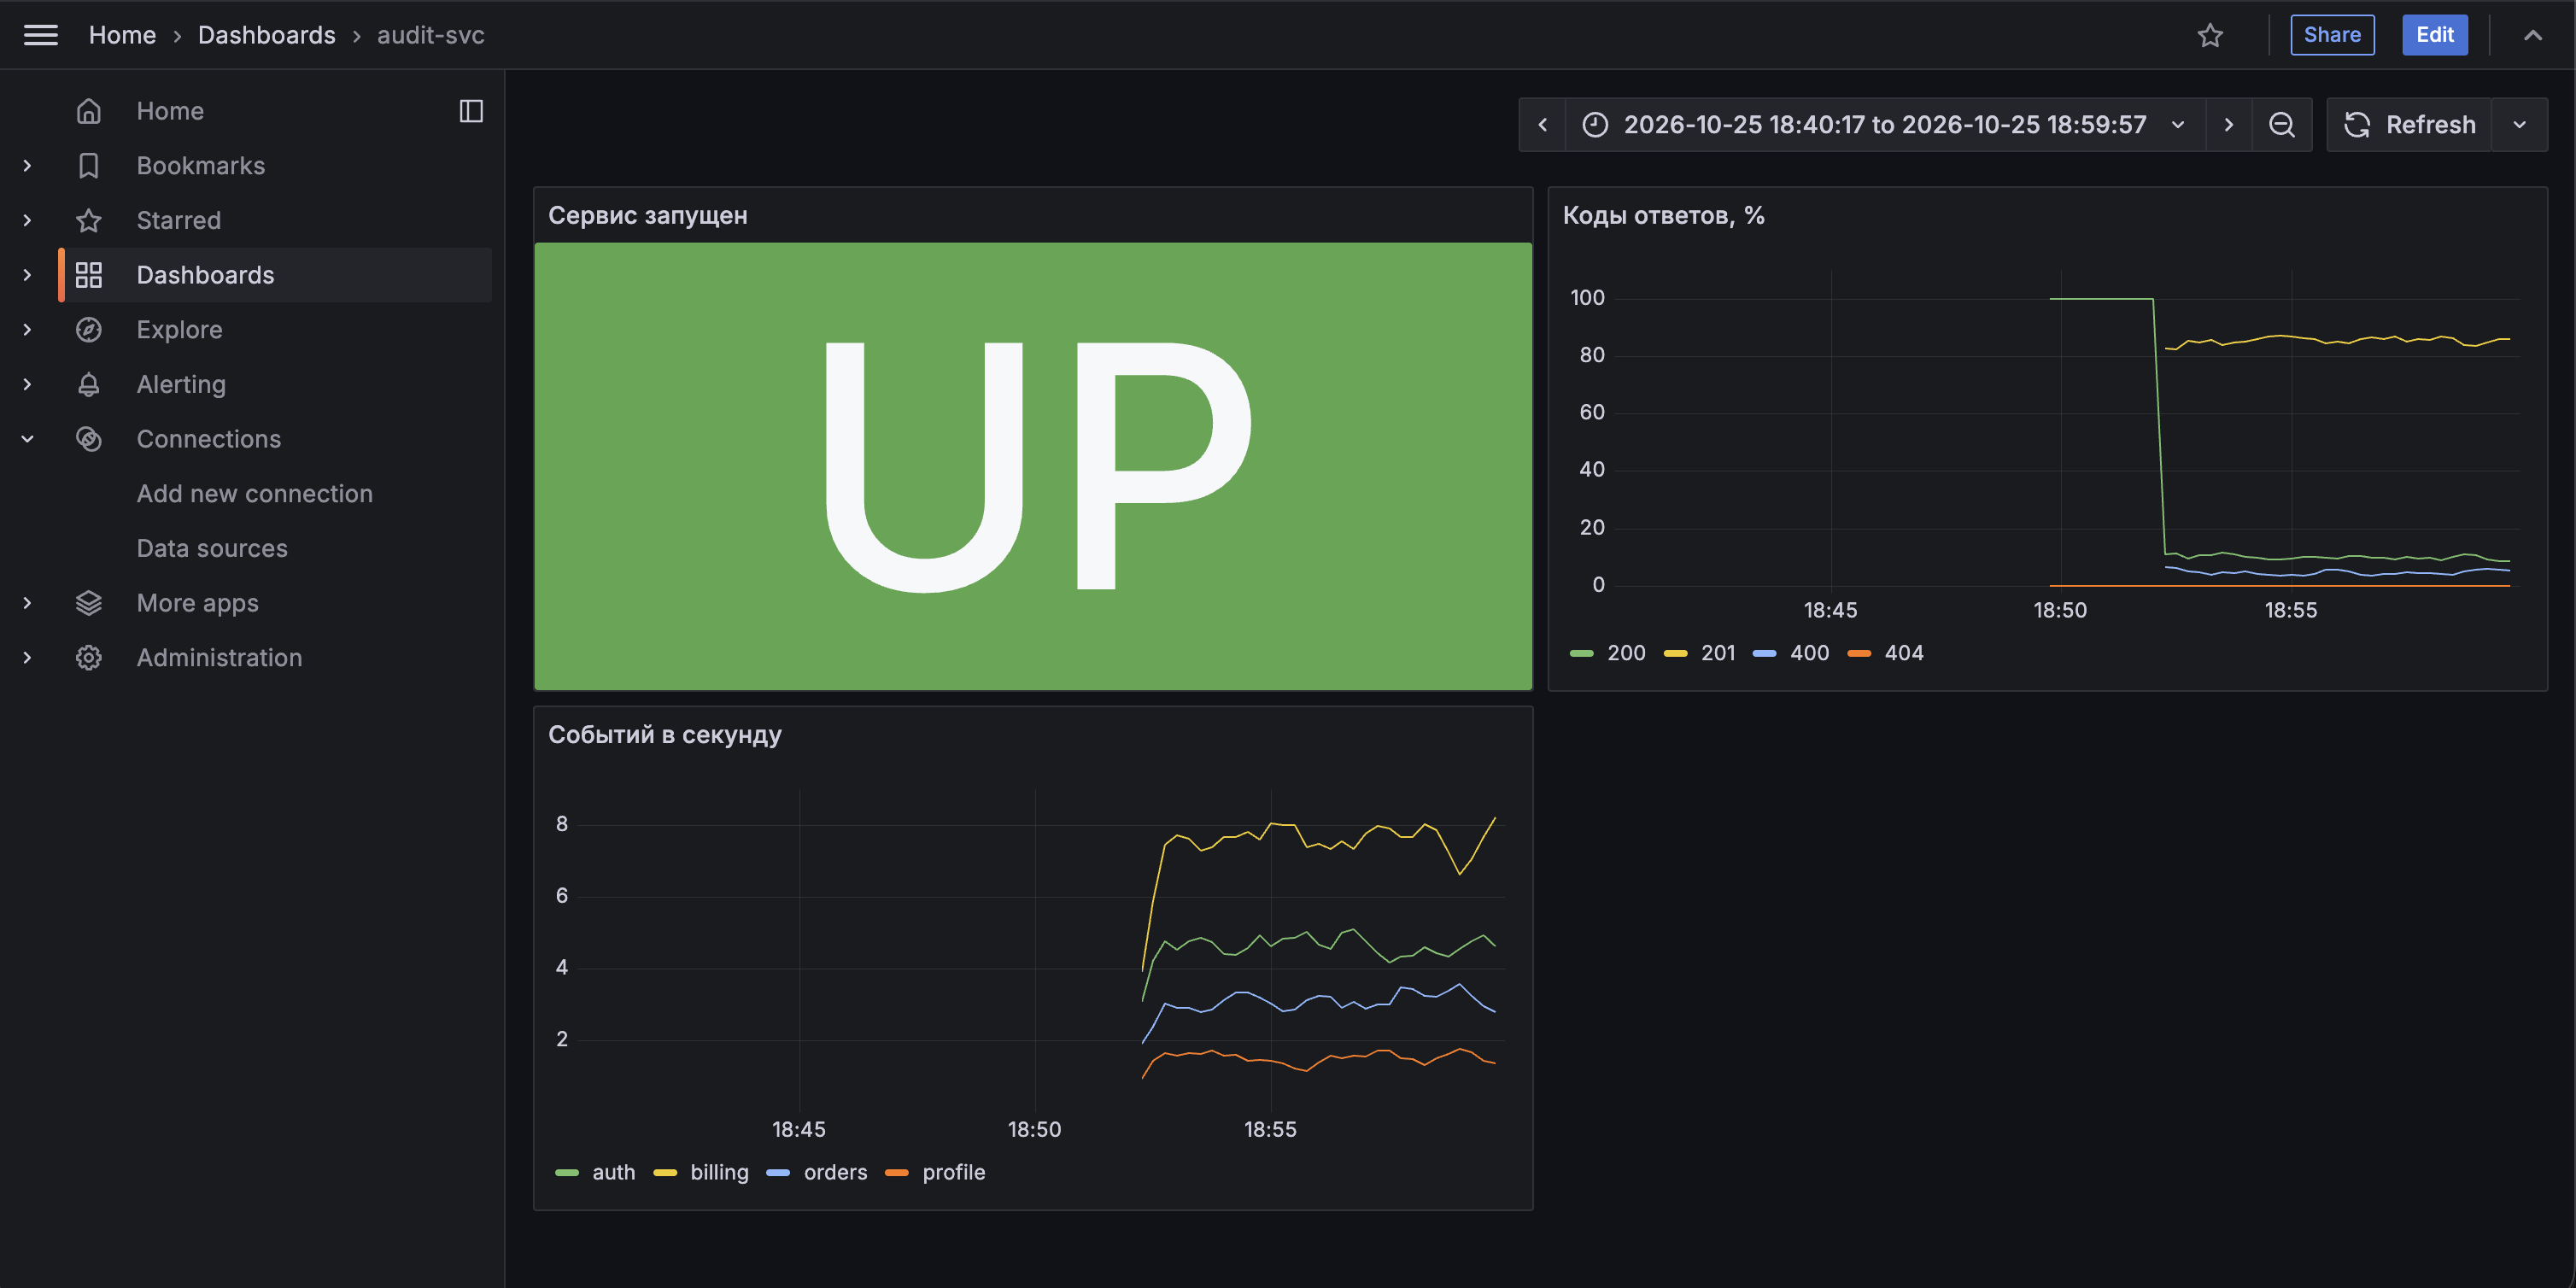

#### Дашборд Nginx
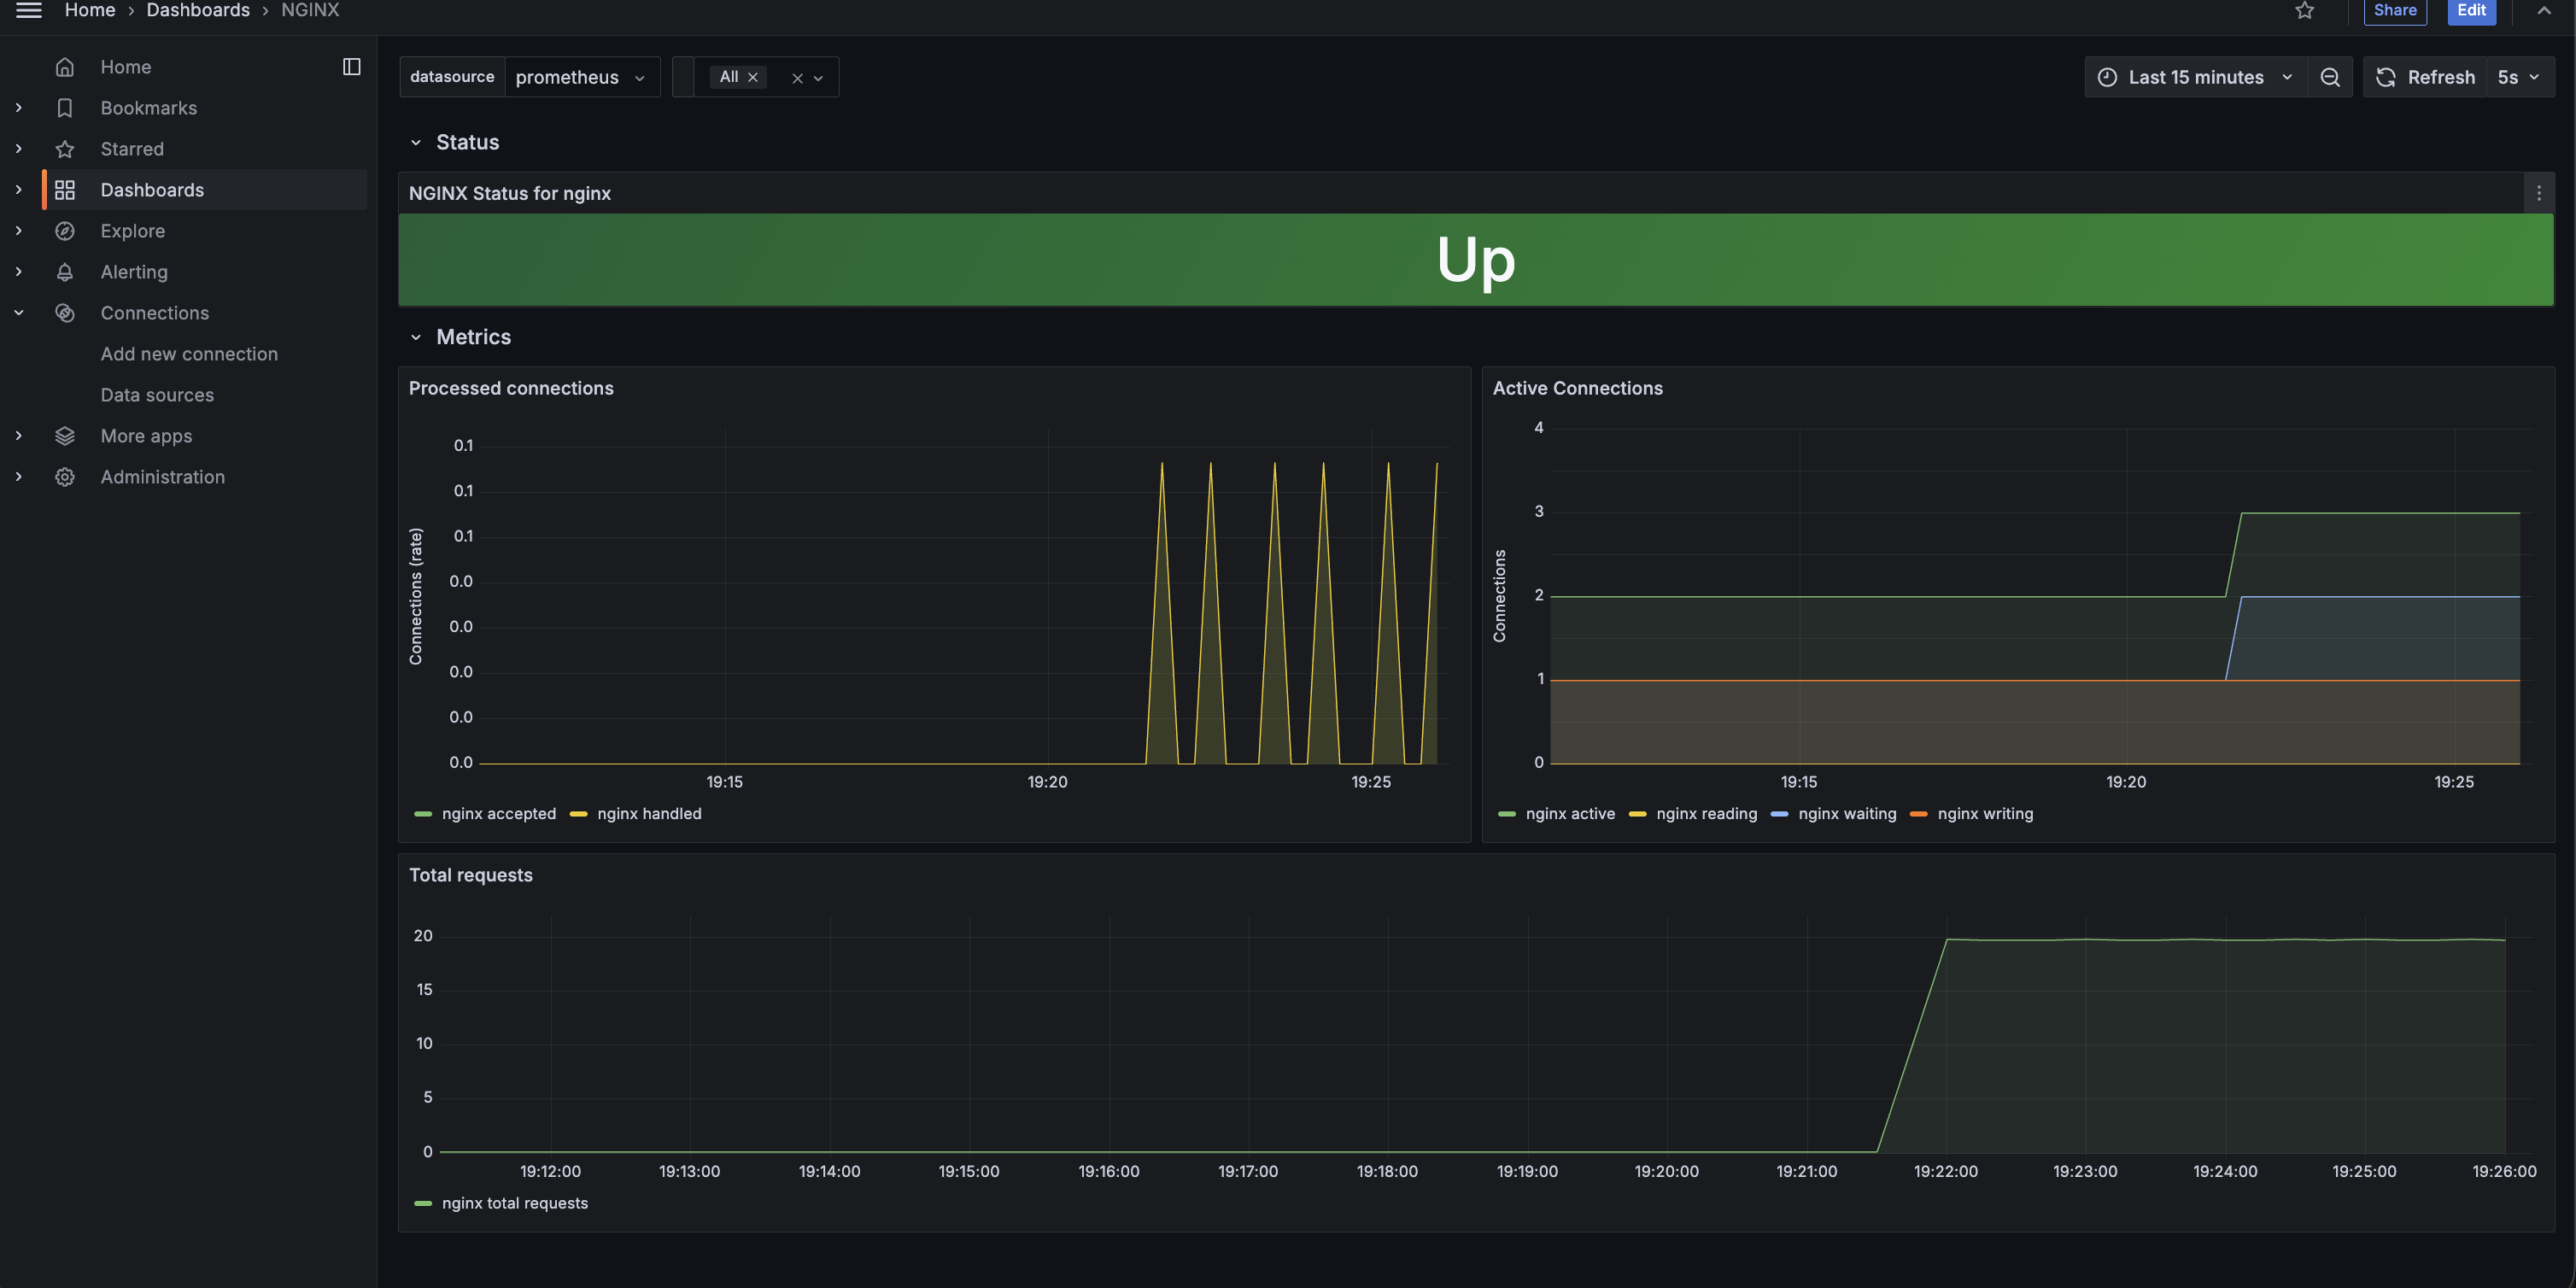

#### Панель «Сервис запущен»
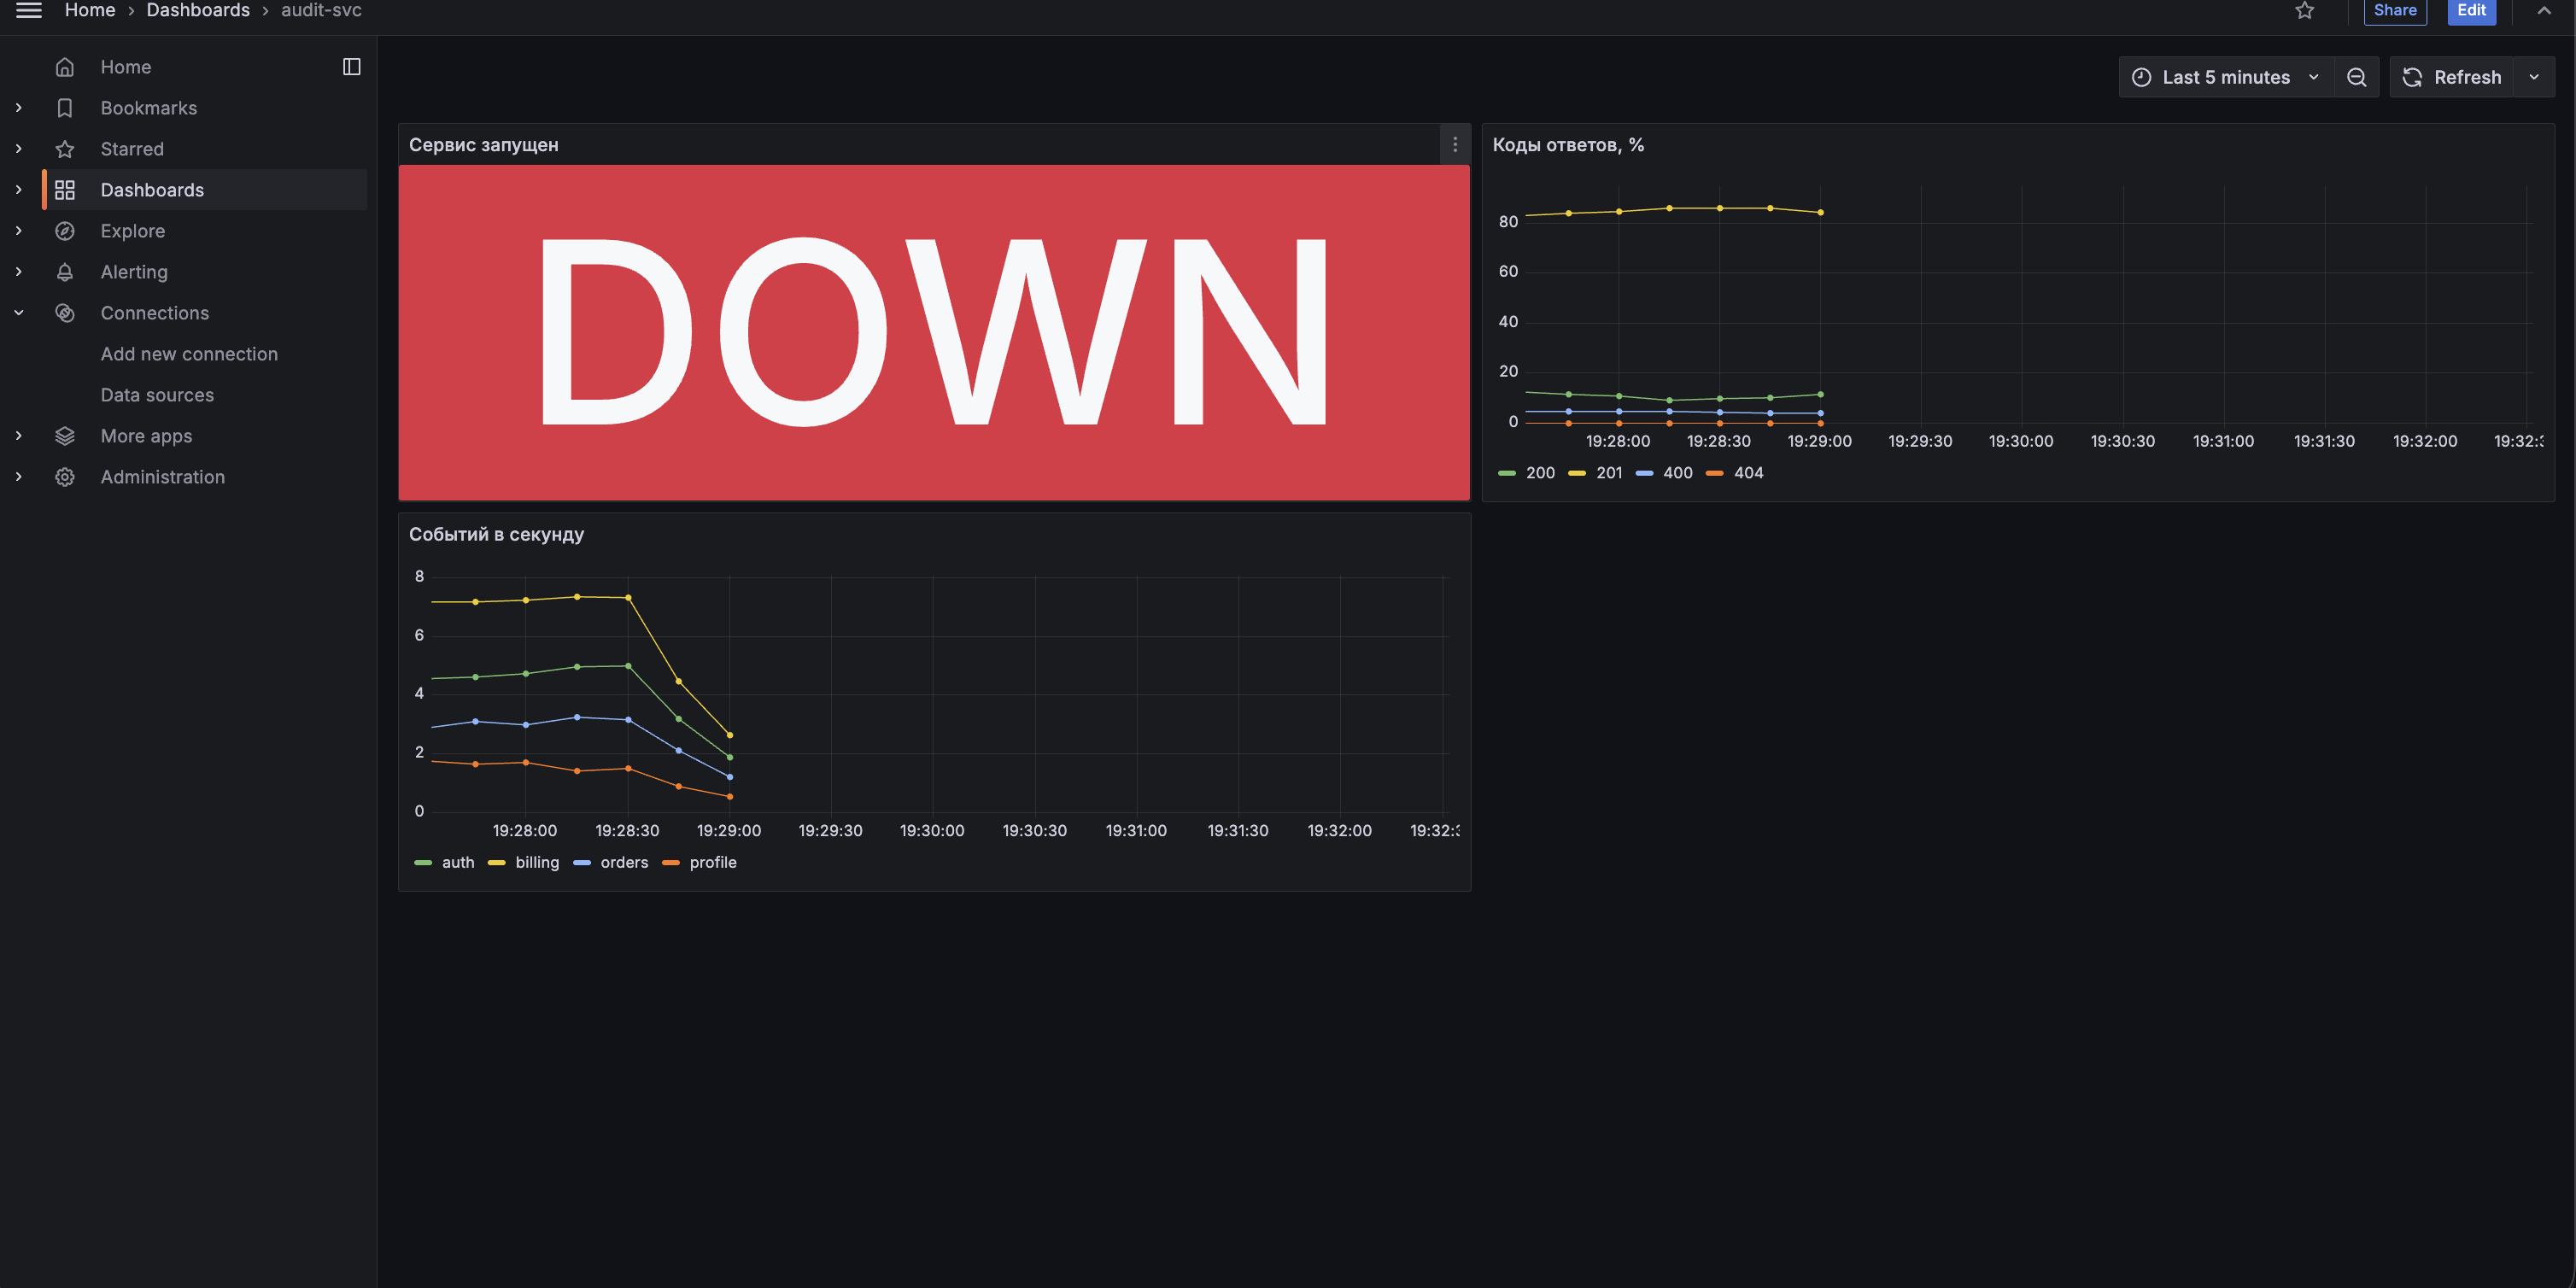
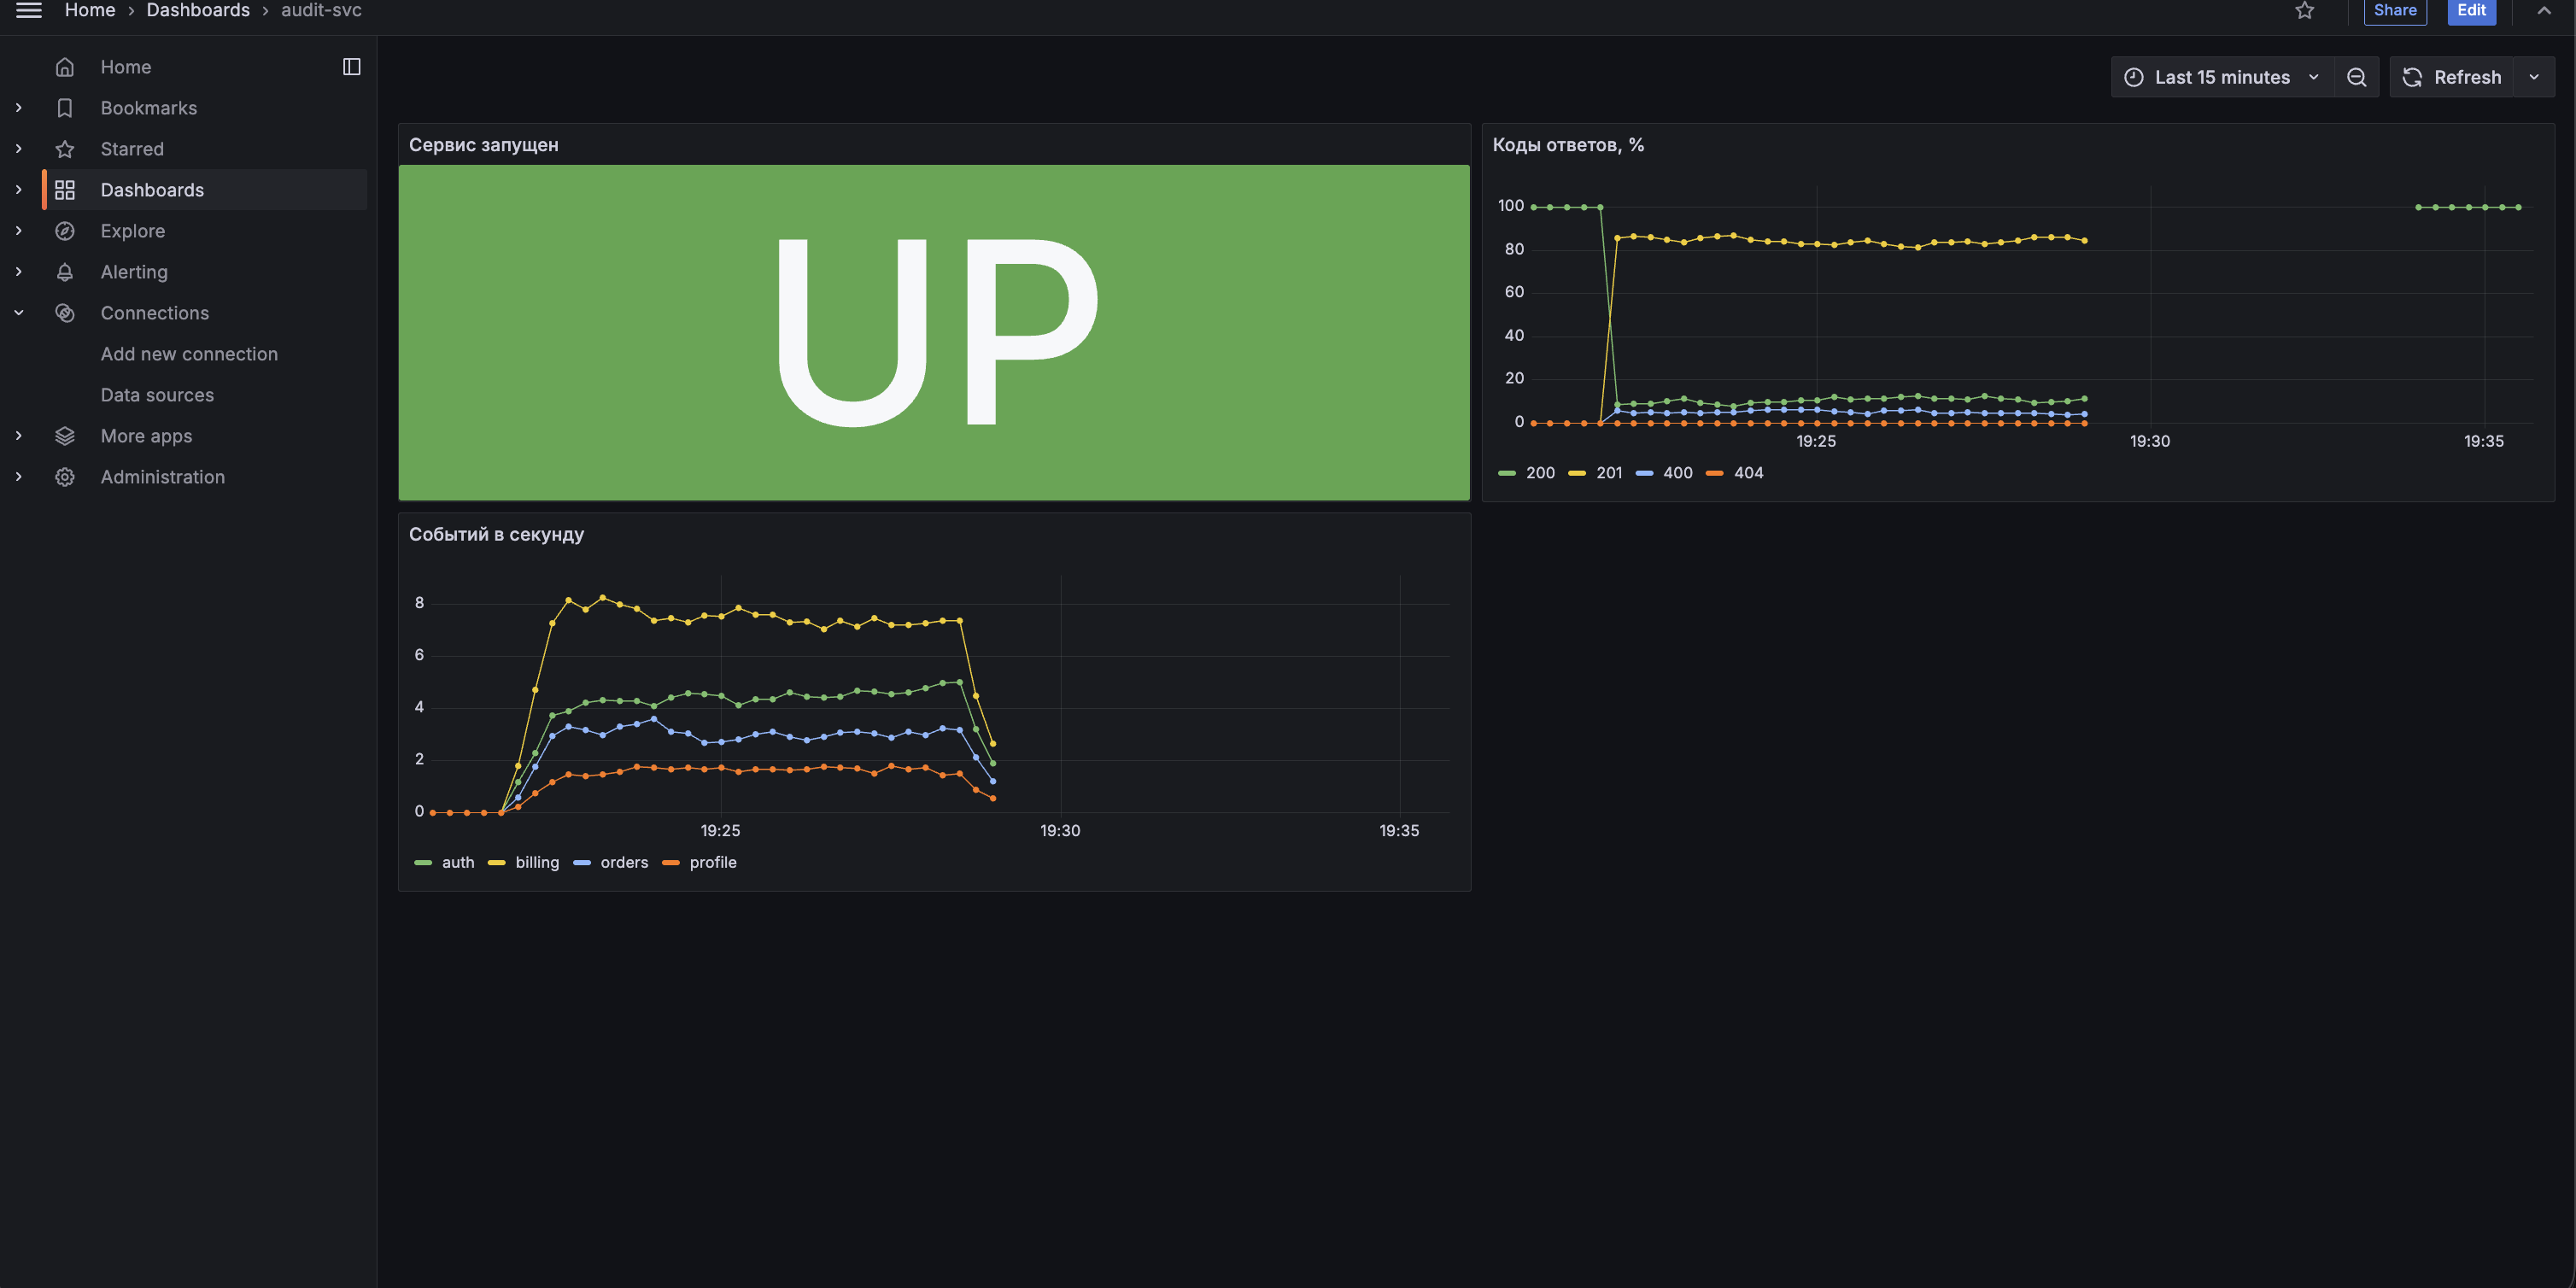

## Миграции при каждом развёртывании

#### Деплой с новой миграцией (тег v0.2.0)

In [22]:
%%bash
ssh -T devopshw << 'EOF'
TOKEN=$(cat ~/stands/lecture4/.state/gitlab-root-token.txt)
API=http://localhost:8929/api/v4/projects/demo%2Faudit-svc
JOB=$(curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs?per_page=100" | jq -r '[.[] | select(.ref=="v0.2.0" and .name=="Deploy")] | sort_by(.id) | .[0].id')
curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs/$JOB/trace" | sed 's/\x1b\[[0-9;]*[mK]//g' | grep -v section_ | sed -n '/PLAY \[/,$p'
EOF

2026-10-25T10:10:03.400818Z 01O PLAY [Deploy audit-svc] ********************************************************
2026-10-25T10:10:03.400820Z 01O 
2026-10-25T10:10:03.400820Z 01O TASK [Gathering Facts] *********************************************************
2026-10-25T10:10:04.406348Z 01O ok: [prom]
2026-10-25T10:10:04.406382Z 01O 
2026-10-25T10:10:04.406383Z 01O TASK [Create docker network] ***************************************************
2026-10-25T10:10:05.069752Z 01O ok: [prom]
2026-10-25T10:10:05.069765Z 01O 
2026-10-25T10:10:05.069765Z 01O TASK [Create config directory] *************************************************
2026-10-25T10:10:05.432787Z 01O ok: [prom]
2026-10-25T10:10:05.432798Z 01O 
2026-10-25T10:10:05.432799Z 01O TASK [Create nginx directory] **************************************************
2026-10-25T10:10:05.701470Z 01O ok: [prom]
2026-10-25T10:10:05.701482Z 01O 
2026-10-25T10:10:05.701484Z 01O TASK [Pull audit-svc image] **************************************

In [23]:
%%bash
ssh -T devopshw << 'EOF'
TOKEN=$(cat ~/stands/lecture4/.state/gitlab-root-token.txt)
API=http://localhost:8929/api/v4/projects/demo%2Faudit-svc
JOB=$(curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs?per_page=100" | jq -r '[.[] | select(.ref=="v0.2.0" and .name=="Deploy")] | sort_by(.id) | .[-1].id')
curl -s --header "PRIVATE-TOKEN: $TOKEN" "$API/jobs/$JOB/trace" | sed 's/\x1b\[[0-9;]*[mK]//g' | grep -v section_ | sed -n '/PLAY \[/,$p'
EOF

2026-10-25T10:16:44.125096Z 01O PLAY [Deploy audit-svc] ********************************************************
2026-10-25T10:16:44.125098Z 01O 
2026-10-25T10:16:44.125099Z 01O TASK [Gathering Facts] *********************************************************
2026-10-25T10:16:45.104252Z 01O ok: [prom]
2026-10-25T10:16:45.104263Z 01O 
2026-10-25T10:16:45.104264Z 01O TASK [Create docker network] ***************************************************
2026-10-25T10:16:45.710383Z 01O ok: [prom]
2026-10-25T10:16:45.710393Z 01O 
2026-10-25T10:16:45.710394Z 01O TASK [Create config directory] *************************************************
2026-10-25T10:16:46.077691Z 01O ok: [prom]
2026-10-25T10:16:46.077701Z 01O 
2026-10-25T10:16:46.077702Z 01O TASK [Create nginx directory] **************************************************
2026-10-25T10:16:46.316252Z 01O ok: [prom]
2026-10-25T10:16:46.316262Z 01O 
2026-10-25T10:16:46.316263Z 01O TASK [Pull audit-svc image] **************************************

#### Индекс в базе

In [24]:
%%bash
ssh -T devopshw << 'EOF'
docker exec deploy-vm docker exec audit-postgres psql -U postgres -d audit -c '\di'
EOF

                              List of relations
 Schema |            Name            | Type  |   Owner   |       Table       
--------+----------------------------+-------+-----------+-------------------
 public | events_actor_idx           | index | audit_svc | events
 public | events_app_received_at_idx | index | audit_svc | events
 public | events_pkey                | index | audit_svc | events
 public | schema_migrations_pkey     | index | audit_svc | schema_migrations
(4 rows)



In [25]:
%%bash
ssh -T devopshw << 'EOF'
docker exec deploy-vm docker exec audit-postgres psql -U postgres -d audit -c 'SELECT version FROM schema_migrations ORDER BY version' -c "SELECT indexname, indexdef FROM pg_indexes WHERE tablename = 'events'"
EOF

         version         
-------------------------
 0001_create_events
 0002_events_app_index
 0003_events_actor_index
(3 rows)

         indexname          |                                        indexdef                                         
----------------------------+-----------------------------------------------------------------------------------------
 events_pkey                | CREATE UNIQUE INDEX events_pkey ON public.events USING btree (id)
 events_app_received_at_idx | CREATE INDEX events_app_received_at_idx ON public.events USING btree (app, received_at)
 events_actor_idx           | CREATE INDEX events_actor_idx ON public.events USING btree (actor)
(3 rows)

